In [70]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [71]:
import pandas as pd

df = pd.read_csv(
    "/kaggle/input/datasets/nytsoul/diabetes/diabetes_data_upload.csv"
)

print(df.head())
print(df.columns.tolist())
print(df.shape)

   Age Gender Polyuria Polydipsia sudden weight loss weakness Polyphagia  \
0   40   Male       No        Yes                 No      Yes         No   
1   58   Male       No         No                 No      Yes         No   
2   41   Male      Yes         No                 No      Yes        Yes   
3   45   Male       No         No                Yes      Yes        Yes   
4   60   Male      Yes        Yes                Yes      Yes        Yes   

  Genital thrush visual blurring Itching Irritability delayed healing  \
0             No              No     Yes           No             Yes   
1             No             Yes      No           No              No   
2             No              No     Yes           No             Yes   
3            Yes              No     Yes           No             Yes   
4             No             Yes     Yes          Yes             Yes   

  partial paresis muscle stiffness Alopecia Obesity     class  
0              No              Yes      

# TASK 1: Load dataset
df = pd.read_csv("/kaggle/input/datasets/nytsoul/diabetes/diabetes_data_upload.csv")
df.columns = df.columns.str.strip()

print("First 5 rows:")
print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:\n", df.isnull().sum())



In [72]:
df = pd.read_csv("/kaggle/input/datasets/nytsoul/diabetes/diabetes_data_upload.csv") 
df.columns = df.columns.str.strip()

print("First 5 rows:") 
print(df.head()) 
print("Shape:", df.shape) 
print("Columns:", df.columns.tolist()) 
print("Missing values:\n", df.isnull().sum())

First 5 rows:
   Age Gender Polyuria Polydipsia sudden weight loss weakness Polyphagia  \
0   40   Male       No        Yes                 No      Yes         No   
1   58   Male       No         No                 No      Yes         No   
2   41   Male      Yes         No                 No      Yes        Yes   
3   45   Male       No         No                Yes      Yes        Yes   
4   60   Male      Yes        Yes                Yes      Yes        Yes   

  Genital thrush visual blurring Itching Irritability delayed healing  \
0             No              No     Yes           No             Yes   
1             No             Yes      No           No              No   
2             No              No     Yes           No             Yes   
3            Yes              No     Yes           No             Yes   
4             No             Yes     Yes          Yes             Yes   

  partial paresis muscle stiffness Alopecia Obesity     class  
0              No         

Target column: class

Class distribution:
class
Positive    320
Negative    200
Name: count, dtype: int64


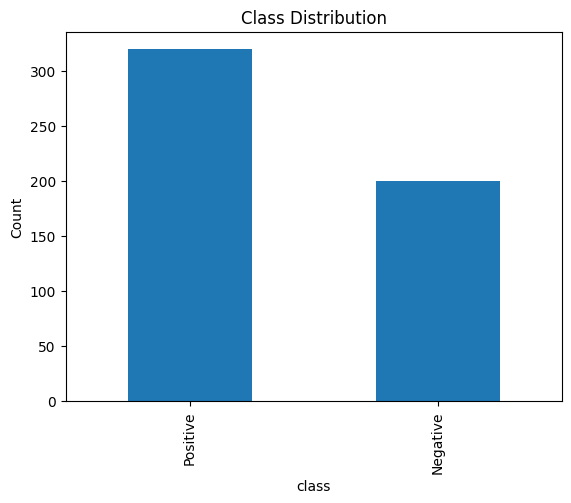

In [73]:
df=pd.read_csv("/kaggle/input/datasets/nytsoul/diabetes/diabetes_data_upload.csv")
df.columns=df.columns.str.strip()

target_candidates = [
    "class", "label", "target", "outcome", "attrition"
]

df.columns = df.columns.str.strip()

target = next(
    (col for col in df.columns
     if col.lower() in target_candidates),
    None
)

if target is None:
    print("Available columns:", df.columns.tolist())
    raise ValueError("No recognized target column found.")

print("Target column:", target)
print("\nClass distribution:")
print(df[target].value_counts())

df[target].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel(target)
plt.ylabel("Count")
plt.show()

In [74]:

# TASK 3: Remove irrelevant columns

df = df.dropna(subset=[target]).copy()

# OUTPUT
print("Irrelevant columns removed successfully.")
print("Missing target values removed successfully.")
print("\nDataset after cleaning:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nRemaining columns:", df.columns.tolist())


Irrelevant columns removed successfully.
Missing target values removed successfully.

Dataset after cleaning:
   Age Gender Polyuria Polydipsia sudden weight loss weakness Polyphagia  \
0   40   Male       No        Yes                 No      Yes         No   
1   58   Male       No         No                 No      Yes         No   
2   41   Male      Yes         No                 No      Yes        Yes   
3   45   Male       No         No                Yes      Yes        Yes   
4   60   Male      Yes        Yes                Yes      Yes        Yes   

  Genital thrush visual blurring Itching Irritability delayed healing  \
0             No              No     Yes           No             Yes   
1             No             Yes      No           No              No   
2             No              No     Yes           No             Yes   
3            Yes              No     Yes           No             Yes   
4             No             Yes     Yes          Yes             Ye

In [75]:

# TASK 4: Separate features (X) and target (y)

X = df.drop(columns=[target]).copy()
y = df[target].astype(str).str.strip()

# OUTPUT
print("Features (X) created successfully.")
print("Target (y) created successfully.")

print("\nFirst 5 rows of features (X):")
print(X.head())

print("\nFirst 5 values of target (y):")
print(y.head())

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)


Features (X) created successfully.
Target (y) created successfully.

First 5 rows of features (X):
   Age Gender Polyuria Polydipsia sudden weight loss weakness Polyphagia  \
0   40   Male       No        Yes                 No      Yes         No   
1   58   Male       No         No                 No      Yes         No   
2   41   Male      Yes         No                 No      Yes        Yes   
3   45   Male       No         No                Yes      Yes        Yes   
4   60   Male      Yes        Yes                Yes      Yes        Yes   

  Genital thrush visual blurring Itching Irritability delayed healing  \
0             No              No     Yes           No             Yes   
1             No             Yes      No           No              No   
2             No              No     Yes           No             Yes   
3            Yes              No     Yes           No             Yes   
4             No             Yes     Yes          Yes             Yes   

  par

In [76]:

# TASK 5: Encode categorical features

X = pd.get_dummies(X, drop_first=True, dtype=int)

# OUTPUT
print("Categorical features encoded successfully.")

print("\nFirst 5 rows after encoding:")
print(X.head())

print("\nDataset shape after encoding:", X.shape)

print("\nRemaining categorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())


Categorical features encoded successfully.

First 5 rows after encoding:
   Age  Gender_Male  Polyuria_Yes  Polydipsia_Yes  sudden weight loss_Yes  \
0   40            1             0               1                       0   
1   58            1             0               0                       0   
2   41            1             1               0                       0   
3   45            1             0               0                       1   
4   60            1             1               1                       1   

   weakness_Yes  Polyphagia_Yes  Genital thrush_Yes  visual blurring_Yes  \
0             1               0                   0                    0   
1             1               0                   0                    1   
2             1               1                   0                    0   
3             1               1                   1                    0   
4             1               1                   0                    1   

   Itch

In [77]:

# TASK 6: Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# OUTPUT
print("Dataset split successfully.")

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


Dataset split successfully.

Training features shape: (416, 16)
Testing features shape: (104, 16)
Training target shape: (416,)
Testing target shape: (104,)

Training samples: 416
Testing samples: 104


In [78]:

# TASK 7: Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# OUTPUT
print("Feature scaling completed successfully!")

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFirst 5 scaled training samples:")
print(X_train[:5])


Feature scaling completed successfully!

Training data shape: (416, 16)
Testing data shape: (104, 16)

First 5 scaled training samples:
[[ 9.92843473e-01 -1.30433842e+00  1.00966206e+00 -8.86232320e-01
   1.16201656e+00  8.18952215e-01 -9.25820100e-01  1.83819133e+00
   1.10125654e+00  1.02927447e+00 -5.40301273e-01  1.06458129e+00
   1.14503760e+00  1.29764054e+00 -7.12212312e-01  2.16763238e+00]
 [ 3.05507078e+00  7.66672198e-01  1.00966206e+00  1.12837230e+00
   1.16201656e+00  8.18952215e-01  1.08012345e+00  1.83819133e+00
   1.10125654e+00  1.02927447e+00 -5.40301273e-01  1.06458129e+00
   1.14503760e+00  1.29764054e+00 -7.12212312e-01 -4.61332839e-01]
 [ 2.97436631e-03  7.66672198e-01  1.00966206e+00  1.12837230e+00
   1.16201656e+00 -1.22107246e+00  1.08012345e+00  1.83819133e+00
  -9.08053635e-01 -9.71558147e-01 -5.40301273e-01  1.06458129e+00
  -8.73333765e-01 -7.70629439e-01 -7.12212312e-01 -4.61332839e-01]
 [-5.74449279e-01  7.66672198e-01  1.00966206e+00  1.12837230e+00
   

In [83]:

# TASK 8: SVM Model Training

from sklearn.svm import SVC

# Create SVM classifier
svm_model = SVC(kernel="linear", random_state=42)

# Train the model
svm_model.fit(X_train, y_train)

# OUTPUT
print("SVM model trained successfully!")
print("Kernel used: Linear")
print("Training samples:", X_train.shape[0])
print("Number of features:", X_train.shape[1])

# Predict test data
y_pred = svm_model.predict(X_test)

print("\nFirst 10 actual values:")
print(y_test[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())


SVM model trained successfully!
Kernel used: Linear
Training samples: 416
Number of features: 16

First 10 actual values:
['Negative', 'Positive', 'Positive', 'Negative', 'Negative', 'Positive', 'Positive', 'Negative', 'Positive', 'Negative']

First 10 predicted values:
['Negative', 'Positive', 'Positive', 'Negative', 'Negative', 'Positive', 'Positive', 'Negative', 'Positive', 'Negative']


SVM Model Evaluation
--------------------
Accuracy  : 0.9327
Precision : 0.9383
Recall    : 0.9327
F1-Score  : 0.9333

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.97      0.92        40
    Positive       0.98      0.91      0.94        64

    accuracy                           0.93       104
   macro avg       0.92      0.94      0.93       104
weighted avg       0.94      0.93      0.93       104



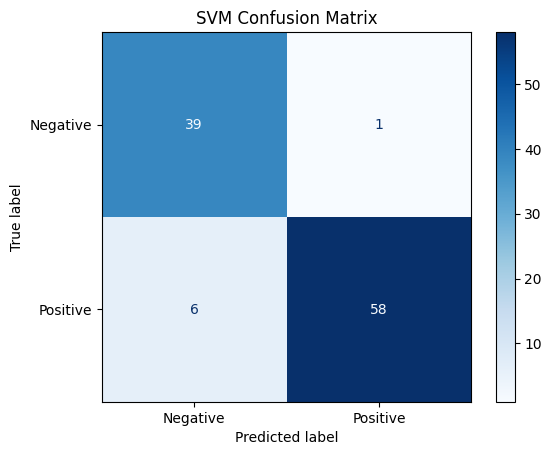

In [79]:

# TASK 9: SVM Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# Print output
print("SVM Model Evaluation")
print("--------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=svm_model.classes_
)
disp.plot(cmap="Blues")
plt.title("SVM Confusion Matrix")
plt.show()



In [80]:

# TASK 10: SVM Kernel Comparison

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

kernels = ["linear", "poly", "rbf"]
results = {}

print("SVM Kernel Comparison")
print("---------------------")

for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    results[kernel] = accuracy

    print(f"{kernel.capitalize()} Kernel Accuracy: {accuracy:.4f}")

# Find the best kernel
best_kernel = max(results, key=results.get)

print("\nBest Kernel:", best_kernel.capitalize())
print("Best Accuracy:", f"{results[best_kernel]:.4f}")


SVM Kernel Comparison
---------------------
Linear Kernel Accuracy: 0.9231
Poly Kernel Accuracy: 0.9712
Rbf Kernel Accuracy: 0.9808

Best Kernel: Rbf
Best Accuracy: 0.9808


In [81]:
# TASK 10: SVM Kernel Comparison

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

for k in ["linear", "poly", "rbf"]:
    model = SVC(kernel=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(k, "Accuracy:", accuracy_score(y_test, pred))

linear Accuracy: 0.9230769230769231
poly Accuracy: 0.9711538461538461
rbf Accuracy: 0.9807692307692307


In [82]:

# TASK 11: SVM Cross-Validation

from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import numpy as np

# Create SVM pipeline
svm_cv = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

# Perform 5-fold cross-validation
cv_scores = cross_val_score(
    svm_cv,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

# OUTPUT
print("SVM Cross-Validation Results")
print("----------------------------")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i} Accuracy: {score:.4f}")

print("\nMean Accuracy:", f"{np.mean(cv_scores):.4f}")
print("Standard Deviation:", f"{np.std(cv_scores):.4f}")


SVM Cross-Validation Results
----------------------------
Fold 1 Accuracy: 0.9524
Fold 2 Accuracy: 0.9277
Fold 3 Accuracy: 0.8795
Fold 4 Accuracy: 0.9639
Fold 5 Accuracy: 0.8675

Mean Accuracy: 0.9182
Standard Deviation: 0.0385
